# Experiment: Mental Health SQL Analysis

## Objective
Create a SQL-first version of the project by loading the cleaned mental-health panel into SQLite and answering portfolio-style questions with analytical SQL.

This notebook keeps the same business flow as the main analysis:

- global trend analysis
- country change analysis
- gender-gap analysis
- DALY burden analysis
- advanced SQL with window functions and ranking


In [1]:
from pathlib import Path

# Repo root is the parent of notebooks/, regardless of the notebook's cwd.
DATA_DIR = Path.cwd().resolve().parent / 'data'


In [2]:
# Import the libraries used for the SQL companion notebook.
import re
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from IPython.display import display


In [3]:
# Set display options for SQL outputs.
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
sns.set_theme(style='whitegrid')

START_YEAR = 1990
END_YEAR = 2019


## Plan

1. Rebuild the cleaned country-year panel used in the main notebook.
2. Load it into an in-memory SQLite database.
3. Read reusable SQL blocks from the companion `.sql` file.
4. Execute the main project questions through compact notebook cells.


In [4]:
# Reuse the same country filter helper as the main notebook.
def keep_countries(df):
    # Drop years outside the common project window.
    df = df[df['Year'].between(START_YEAR, END_YEAR)].copy()
    code = df['Code'].astype(str)
    # Remove aggregate OWID regions so the SQL table stays country-level.
    return df[df['Code'].notna() & ~code.str.startswith('OWID_')].copy()


In [5]:
# Load and rename the total mental-disorder prevalence table.
mental = keep_countries(pd.read_csv(DATA_DIR / 'share-with-mental-and-substance-disorders.csv')).rename(columns={
    'Prevalence - Mental disorders - Sex: Both - Age: Age-standardized (Percent)': 'mental_prev'
})


In [6]:
# Load and rename the depression prevalence table.
depression = keep_countries(pd.read_csv(DATA_DIR / 'share-with-depression.csv')).rename(columns={
    'Prevalence - Depressive disorders - Sex: Both - Age: Age-standardized (Percent)': 'depression_prev'
})


In [7]:
# Load and rename the DALY burden table.
daly = keep_countries(pd.read_csv(DATA_DIR / 'mental-and-substance-use-as-share-of-disease.csv')).rename(columns={
    'DALYs (Disability-Adjusted Life Years) - Mental disorders - Sex: Both - Age: All Ages (Percent)': 'daly_share'
})


In [8]:
# Define shorter names for the mood and psychosis prevalence columns.
disorder_rename_map = {
    'Prevalence - Schizophrenia - Sex: Both - Age: Age-standardized (Percent)': 'schizophrenia_prev',
    'Prevalence - Bipolar disorder - Sex: Both - Age: Age-standardized (Percent)': 'bipolar_prev',
    'Prevalence - Eating disorders - Sex: Both - Age: Age-standardized (Percent)': 'eating_prev',
    'Prevalence - Anxiety disorders - Sex: Both - Age: Age-standardized (Percent)': 'anxiety_prev',
}


In [9]:
# Add the remaining substance-use and depression column labels.
disorder_rename_map.update({
    'Prevalence - Drug use disorders - Sex: Both - Age: Age-standardized (Percent)': 'drug_prev',
    'Prevalence - Depressive disorders - Sex: Both - Age: Age-standardized (Percent)': 'depressive_prev',
    'Prevalence - Alcohol use disorders - Sex: Both - Age: Age-standardized (Percent)': 'alcohol_prev',
})


In [10]:
# Load and rename the disorder-level prevalence table.
disorders = keep_countries(pd.read_csv(DATA_DIR / 'prevalence-by-mental-and-substance-use-disorder.csv')).rename(columns=disorder_rename_map)


In [11]:
# Load the depression-by-sex table for population and gender-gap features.
depression_by_sex = keep_countries(pd.read_csv(DATA_DIR / 'prevalence-of-depression-males-vs-females.csv')).rename(columns={
    'Prevalence - Depressive disorders - Sex: Male - Age: Age-standardized (Percent)': 'depression_male_prev',
    'Prevalence - Depressive disorders - Sex: Female - Age: Age-standardized (Percent)': 'depression_female_prev',
    'Population (historical estimates)': 'population',
    'Continent': 'continent',
})


In [12]:
# Create the continent lookup used in the SQL panel.
continent_map = depression_by_sex[['Code', 'continent']].dropna().drop_duplicates('Code')


In [13]:
# Start the SQL panel with total mental prevalence.
panel_df = mental[['Entity', 'Code', 'Year', 'mental_prev']].copy()


In [14]:
# Add overall depression prevalence into the SQL panel.
panel_df = panel_df.merge(
    depression[['Entity', 'Code', 'Year', 'depression_prev']],
    on=['Entity', 'Code', 'Year'],
    how='inner',
)


In [15]:
# Add DALY burden into the SQL panel.
panel_df = panel_df.merge(
    daly[['Entity', 'Code', 'Year', 'daly_share']],
    on=['Entity', 'Code', 'Year'],
    how='inner',
)


In [16]:
# Add disorder-level prevalence columns into the SQL panel.
panel_df = panel_df.merge(
    disorders[[
        'Entity', 'Code', 'Year', 'schizophrenia_prev', 'bipolar_prev', 'eating_prev',
        'anxiety_prev', 'drug_prev', 'depressive_prev', 'alcohol_prev'
    ]],
    on=['Entity', 'Code', 'Year'],
    how='inner',
)


In [17]:
# Attach population and sex-specific depression columns.
panel_df = panel_df.merge(
    depression_by_sex[[
        'Entity', 'Code', 'Year', 'depression_male_prev', 'depression_female_prev', 'population'
    ]],
    on=['Entity', 'Code', 'Year'],
    how='left',
)


In [18]:
# Attach continent labels so SQL groupings can roll up by region.
panel_df = panel_df.merge(continent_map, on='Code', how='left')


In [19]:
# Create the SQL-friendly gender-gap feature.
panel_df['depression_gender_gap'] = panel_df['depression_female_prev'] - panel_df['depression_male_prev']


In [20]:
# Create the burden ratio used in the advanced SQL queries.
panel_df['burden_ratio'] = panel_df['daly_share'] / panel_df['mental_prev']


In [21]:
# Preview the SQL-ready panel before loading it into SQLite.
display(panel_df.head())


,Entity,Code,Year,mental_prev,depression_prev,daly_share,schizophrenia_prev,bipolar_prev,eating_prev,anxiety_prev,drug_prev,depressive_prev,alcohol_prev,depression_male_prev,depression_female_prev,population,continent,depression_gender_gap,burden_ratio
0,Afghanistan,AFG,1990,16.6592,5.1253,1.6967,0.2290,0.7212,0.1310,4.8351,0.4542,5.1253,0.4440,4.2911,5.8597,"12,412,311.0000",Asia,1.5686,0.1018
1,Afghanistan,AFG,1991,16.7651,5.1163,1.7343,0.2281,0.7200,0.1264,4.8218,0.4471,5.1163,0.4442,4.2933,5.8531,"13,299,016.0000",Asia,1.5598,0.1034
2,Afghanistan,AFG,1992,16.8745,5.1066,1.7912,0.2273,0.7184,0.1218,4.8014,0.4412,5.1066,0.4455,4.2983,5.8500,"14,485,543.0000",Asia,1.5518,0.1061
3,Afghanistan,AFG,1993,16.9907,5.1003,1.7768,0.2265,0.7175,0.1179,4.7894,0.4356,5.1003,0.4460,4.3031,5.8450,"15,816,601.0000",Asia,1.5419,0.1046
4,Afghanistan,AFG,1994,17.1127,5.0994,1.7130,0.2256,0.7170,0.1145,4.7849,0.4318,5.0994,0.4458,4.3061,5.8436,"17,075,728.0000",Asia,1.5376,0.1001


In [22]:
# Create the in-memory SQLite database.
conn = sqlite3.connect(':memory:')


In [23]:
# Load the panel into SQLite as mental_health_panel.
panel_df.to_sql('mental_health_panel', conn, index=False, if_exists='replace')


6060

In [24]:
# Define a small helper for running SQL and returning a DataFrame.
def run_query(query):
    # Returning a DataFrame keeps the SQL results easy to chart and compare.
    return pd.read_sql_query(query, conn)


In [25]:
# Inspect the SQLite schema before running the project queries.
display(run_query("PRAGMA table_info(mental_health_panel);"))


,cid,name,type,notnull,dflt_value,pk
0,0,Entity,TEXT,0,None,0
1,1,Code,TEXT,0,None,0
2,2,Year,INTEGER,0,None,0
3,3,mental_prev,REAL,0,None,0
4,4,depression_prev,REAL,0,None,0
5,5,daly_share,REAL,0,None,0
6,6,schizophrenia_prev,REAL,0,None,0
7,7,bipolar_prev,REAL,0,None,0
8,8,eating_prev,REAL,0,None,0
9,9,anxiety_prev,REAL,0,None,0


In [26]:
# Read the reusable SQL script into memory.
sql_script_text = (Path.cwd().resolve().parent / 'sql' / 'queries.sql').read_text()


In [27]:
# Start empty containers for the named SQL query sections.
query_sections = {}
current_title = None
current_lines = []


In [28]:
# Define a helper that stores each completed SQL section.
def store_query(title, lines):
    if not title or not lines:
        return
    key = re.sub(r'[^a-z0-9]+', '_', title.lower()).strip('_')
    query_sections[key] = '\n'.join(lines).strip()


In [29]:
# Walk through the SQL script and collect each numbered section.
for line in sql_script_text.splitlines():
    heading = re.match(r'^--\s+\d+\.\s+(.*)$', line)
    if heading:
        store_query(current_title, current_lines)
        current_title = heading.group(1).strip()
        current_lines = []
    elif current_title and not line.startswith('--'):
        current_lines.append(line)


In [30]:
# Store the final query after the loop finishes.
store_query(current_title, current_lines)


In [31]:
# Preview the available query names loaded from the SQL script.
display(pd.DataFrame({'query_name': sorted(query_sections)}))


,query_name
0,burden_quintiles_using_ntile
1,continent_summary_for_2019
2,countries_with_the_largest_change_in_mental_pr...
3,daly_burden_ranking_in_2019
4,global_yearly_prevalence_trend
5,highest_depression_gender_gaps_in_2019
6,highest_prevalence_countries_in_2019
7,recent_profile_classification_for_2015_to_2019
8,rolling_3_year_average_with_window_functions


## Beginner SQL

Start with the same beginner questions as the Python notebook, but keep each execution step compact.


In [32]:
# Run the yearly global trend query from the SQL script.
global_trend_sql_df = run_query(query_sections['global_yearly_prevalence_trend'])


In [33]:
# Preview the yearly global trend result.
display(global_trend_sql_df.head())
display(global_trend_sql_df.tail())


,Year,avg_mental_prev,weighted_mental_prev,avg_depression_prev
0,1990,13.3237,13.1401,3.9832
1,1991,13.3275,13.1921,3.9812
2,1992,13.3317,13.2384,3.9798
3,1993,13.3356,13.2766,3.9788
4,1994,13.3391,13.3032,3.9785


,Year,avg_mental_prev,weighted_mental_prev,avg_depression_prev
25,2015,13.2848,13.0774,3.9040
26,2016,13.2827,13.0802,3.9041
27,2017,13.2810,13.0843,3.9051
28,2018,13.2824,13.0761,3.9099
29,2019,13.2869,13.0610,3.9185


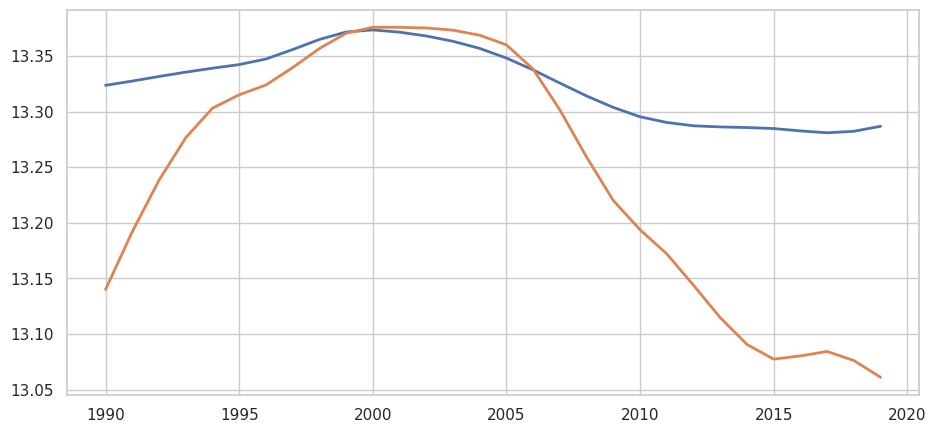

In [34]:
# Start the SQL trend chart and draw the two prevalence lines.
plt.figure(figsize=(11, 5))
plt.plot(global_trend_sql_df['Year'], global_trend_sql_df['avg_mental_prev'], label='Country mean', linewidth=2)
plt.plot(global_trend_sql_df['Year'], global_trend_sql_df['weighted_mental_prev'], label='Population weighted', linewidth=2)


/tmp/ipykernel_1042/1886002501.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


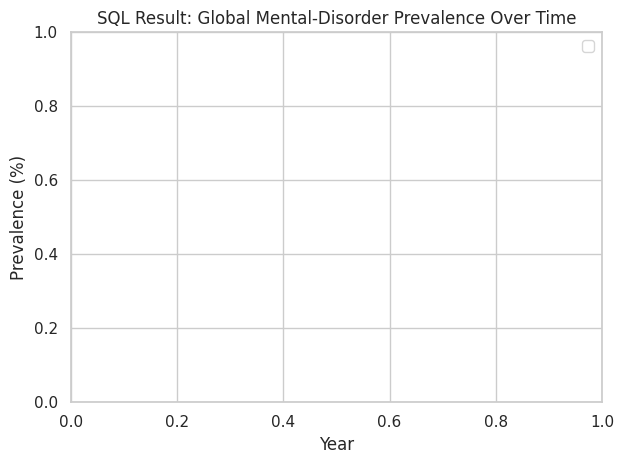

In [35]:
# Label and render the SQL trend chart.
plt.title('SQL Result: Global Mental-Disorder Prevalence Over Time')
plt.xlabel('Year')
plt.ylabel('Prevalence (%)')
plt.legend()
plt.tight_layout()
plt.show()


In [36]:
# Run the country-change ranking query from the SQL script.
country_change_sql_df = run_query(query_sections['countries_with_the_largest_change_in_mental_prevalence_from_1990_to_2019'])


In [37]:
# Display the SQL country-change ranking.
display(country_change_sql_df)


,Entity,Code,mental_prev_1990,mental_prev_2019,abs_change,pct_change
0,United States,USA,15.5565,16.9346,1.3781,8.8590
1,Mexico,MEX,10.9638,12.2617,1.2979,11.8383
2,Brazil,BRA,15.4899,16.7171,1.2271,7.9221
3,New Zealand,NZL,18.0475,19.0366,0.9892,5.4809
4,Spain,ESP,17.4253,18.3197,0.8944,5.1328
...,...,...,...,...,...,...
197,Bosnia and Herzegovina,BIH,12.5323,11.5134,-1.0189,-8.1302
198,Cambodia,KHM,13.4824,12.3609,-1.1215,-8.3185
199,Finland,FIN,16.2765,14.9640,-1.3125,-8.0639
200,Myanmar,MMR,12.2441,10.8869,-1.3572,-11.0843


In [38]:
# Run the top-2019 prevalence query from the SQL script.
top_2019_sql_df = run_query(query_sections['highest_prevalence_countries_in_2019'])


In [39]:
# Display the top-2019 prevalence ranking.
display(top_2019_sql_df)


,Entity,continent,mental_prev,depression_prev,daly_share
0,Australia,Oceania,19.3479,4.8278,9.6268
1,New Zealand,Oceania,19.0366,4.1208,8.6851
2,Iran,Asia,18.8876,5.0960,10.3147
3,Portugal,Europe,18.4513,4.8123,8.2736
4,Spain,Europe,18.3197,5.1917,8.6842
5,Palestine,Asia,18.1397,6.5438,11.0582
6,Ireland,Europe,17.6095,4.6489,9.5293
7,Greenland,North America,17.5429,6.3646,6.9507
8,Afghanistan,Asia,17.1176,5.1315,3.9913
9,Switzerland,Europe,17.0745,4.0847,8.8349


## Intermediate SQL

Use SQL aggregations and rankings to surface gender and burden patterns.


In [40]:
# Run the SQL ranking for the widest depression gender gaps.
gender_gap_sql_df = run_query(query_sections['highest_depression_gender_gaps_in_2019'])


In [41]:
# Display the SQL gender-gap ranking.
display(gender_gap_sql_df)


,Entity,continent,depression_male_prev,depression_female_prev,depression_gender_gap
0,Gambia,Africa,3.2641,7.8953,4.6312
1,Liberia,Africa,2.8654,6.3993,3.5339
2,Spain,Europe,3.5598,6.7367,3.1770
3,Paraguay,South America,2.4286,5.3333,2.9047
4,Greenland,North America,4.9800,7.8243,2.8444
5,Sweden,Europe,3.1236,5.7980,2.6744
6,Portugal,Europe,3.4271,6.0295,2.6024
7,Iran,Asia,3.8494,6.3395,2.4902
8,Jordan,Asia,3.2390,5.7206,2.4815
9,Chile,South America,2.6882,5.1244,2.4361


In [42]:
# Run the SQL continent summary query.
continent_sql_df = run_query(query_sections['continent_summary_for_2019'])


In [43]:
# Display the SQL continent summary.
display(continent_sql_df)


,continent,countries,avg_mental_prev,avg_depression_gap,avg_daly_share
0,South America,12,14.6562,1.6643,6.7032
1,Africa,54,12.6619,1.6542,3.8660
2,North America,27,14.3083,1.6394,6.0682
3,Europe,43,13.9737,1.6158,6.2501
4,Asia,46,12.7621,1.3296,6.3884
5,Oceania,20,12.5039,0.9378,4.3685


In [44]:
# Run the SQL DALY burden ranking.
burden_sql_df = run_query(query_sections['daly_burden_ranking_in_2019'])


In [45]:
# Display the SQL DALY burden ranking.
display(burden_sql_df)


,Entity,continent,mental_prev,daly_share,burden_ratio
0,Qatar,Asia,13.6277,13.6702,1.0031
1,Kuwait,Asia,14.0464,12.2259,0.8704
2,Bahrain,Asia,14.5707,11.4878,0.7884
3,Oman,Asia,13.7301,10.4120,0.7583
4,Maldives,Asia,11.0730,8.0588,0.7278
5,United Arab Emirates,Asia,12.5313,9.0044,0.7186
6,Jordan,Asia,15.0417,10.2431,0.6810
7,Israel,Asia,14.4834,9.6270,0.6647
8,Saudi Arabia,Asia,13.6971,8.9208,0.6513
9,Palestine,Asia,18.1397,11.0582,0.6096


## Advanced SQL

The advanced SQL section reuses the window-function and bucketing queries from the companion script.


In [46]:
# Run the rolling-average window-function query.
rolling_sql_df = run_query(query_sections['rolling_3_year_average_with_window_functions'])


In [47]:
# Display the rolling-average result.
display(rolling_sql_df)


,Entity,Year,mental_prev,mental_prev_3yr_avg,deviation_from_recent_avg
0,Colombia,2017,11.9968,11.6698,0.3270
1,United States,2019,16.9346,16.6858,0.2488
2,Australia,2019,19.3479,19.1274,0.2206
3,Colombia,2016,11.6676,11.4483,0.2192
4,Yemen,2019,16.4015,16.2316,0.1699
5,Yemen,2018,16.2209,16.0741,0.1469
6,Colombia,2018,12.0265,11.8970,0.1296
7,Yemen,2017,16.0724,15.9464,0.1260
8,Syria,2019,16.2795,16.1707,0.1088
9,Mongolia,2017,11.3409,11.2398,0.1011


In [48]:
# Run the burden-quintile query.
quintile_sql_df = run_query(query_sections['burden_quintiles_using_ntile'])


In [49]:
# Display the burden-quintile summary.
display(quintile_sql_df)


,burden_quintile,countries,avg_burden_ratio,min_burden_ratio,max_burden_ratio
0,1,41,0.5867,0.4969,1.0031
1,2,41,0.4600,0.4330,0.4876
2,3,40,0.4024,0.3814,0.4318
3,4,40,0.3399,0.2992,0.3796
4,5,40,0.2317,0.1436,0.2926


In [50]:
# Run the recent-profile classification query.
profile_sql_df = run_query(query_sections['recent_profile_classification_for_2015_to_2019'])


In [51]:
# Display the recent-profile classification summary.
display(profile_sql_df)


,profile_band,countries,avg_mental_prev,avg_daly_share,avg_depression_gap
0,Lower prevalence / Lower burden,142,12.2941,4.3158,1.3804
1,High prevalence / High burden,28,16.6918,8.3545,1.8963
2,Lower prevalence / High burden,18,13.9086,9.0192,1.5156
3,High prevalence / Lower burden,14,15.6993,5.5295,1.8409


## Next Steps

- Keep extending the SQL script if you want additional interview-style queries.
- Swap the in-memory SQLite database for a persistent file or Postgres version if you want a database project variant.
- Add external socioeconomic features later if you want the SQL notebook to mirror a richer modeling setup.
